# Cookie Cats A/B Test: Should the First Gate Move from Level 30 to Level 40?

**Author:** Palak Gupta

**Question:** Does moving the first gate from level 30 (`gate_30`, control) to level 40 (`gate_40`, treatment) change player retention or engagement?

**Data:** 90,189 players from the public Kaggle dataset *Mobile Games A/B Testing - Cookie Cats*.

| Column | Meaning |
| --- | --- |
| `userid` | Unique player ID |
| `version` | `gate_30` (control) or `gate_40` (treatment) |
| `sum_gamerounds` | Rounds played in the first 14 days |
| `retention_1` | Player came back 1 day after install |
| `retention_7` | Player came back 7 days after install |

**Recommendation (details at the end): keep the gate at level 30.**

**How to run:** run all cells from top to bottom. In Google Colab, upload `cookie_cats.csv` when asked. Elsewhere, place the file next to this notebook.

## 1. Setup and load data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower

In [2]:
# Google Colab: upload cookie_cats.csv when prompted. Elsewhere: keep it in the same folder.
if not os.path.exists("cookie_cats.csv"):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError("Place cookie_cats.csv in the same folder as this notebook.")

df = pd.read_csv("cookie_cats.csv")
print(df.head())
print(df.shape)

   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
(90189, 5)


## 2. Data quality checks

- **Duplicates:** the same player should not appear twice.
- **Sample ratio check:** with random assignment the two groups should be about equal in size.

In [3]:
print("Duplicate users:", df["userid"].duplicated().sum())
print(df["version"].value_counts())

counts = df["version"].value_counts()
chi2, p_srm = stats.chisquare(counts.values)
print("SRM p-value:", round(p_srm, 4))

Duplicate users: 0
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
SRM p-value: 0.0086


The check is flagged (p = 0.0086), but the groups are 50.4% vs 49.6%, a gap of only about 0.9 points. With 90,000+ players even a tiny gap looks significant, so the analysis goes ahead and this is noted as a limitation.

## 3. Outliers in rounds played

The rounds data is heavily skewed (mean far above the median), and one player has 49,854 rounds, far above everyone else.

In [4]:
print(df["sum_gamerounds"].describe())
print()
print("Top 5 highest round counts:")
print(df["sum_gamerounds"].sort_values(ascending=False).head())

count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64

Top 5 highest round counts:
57702    49854
7912      2961
29417     2640
43671     2438
48188     2294
Name: sum_gamerounds, dtype: int64


In [5]:
df_clean = df[df["sum_gamerounds"] < df["sum_gamerounds"].max()].copy()
print("Rows before:", len(df))
print("Rows after:", len(df_clean))

Rows before: 90189
Rows after: 90188


## 4. Retention and rounds by group

In [6]:
summary = df_clean.groupby("version").agg(
    users=("userid", "count"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
    median_rounds=("sum_gamerounds", "median"),
    mean_rounds=("sum_gamerounds", "mean"),
)
print(summary)

         users  retention_1  retention_7  median_rounds  mean_rounds
version                                                             
gate_30  44699     0.448198     0.190183           17.0    51.342111
gate_40  45489     0.442283     0.182000           16.0    51.298776


## 5. Two-proportion Z-test (retention)

- **H0:** retention is the same in both groups.
- **H1:** retention differs between the groups.
- Significance level: 0.05

In [7]:
def test_retention(metric):
    control = df_clean[df_clean["version"] == "gate_30"][metric]
    treat = df_clean[df_clean["version"] == "gate_40"][metric]

    successes = np.array([control.sum(), treat.sum()])
    nobs = np.array([len(control), len(treat)])

    z_stat, p_val = proportions_ztest(successes, nobs)

    p_c, p_t = successes / nobs
    diff = p_t - p_c
    se = np.sqrt(p_c*(1-p_c)/nobs[0] + p_t*(1-p_t)/nobs[1])

    print("---", metric, "---")
    print("gate_30:", round(p_c*100, 2), "%")
    print("gate_40:", round(p_t*100, 2), "%")
    print("Difference:", round(diff*100, 2), "percentage points")
    print("p-value:", round(p_val, 4))
    print("95% CI:", round((diff-1.96*se)*100, 2), "to", round((diff+1.96*se)*100, 2))
    if p_val < 0.05:
        print("Result: SIGNIFICANT")
    else:
        print("Result: NOT significant")
    print()

test_retention("retention_1")
test_retention("retention_7")

--- retention_1 ---
gate_30: 44.82 %
gate_40: 44.23 %
Difference: -0.59 percentage points
p-value: 0.0739
95% CI: -1.24 to 0.06
Result: NOT significant

--- retention_7 ---
gate_30: 19.02 %
gate_40: 18.2 %
Difference: -0.82 percentage points
p-value: 0.0016
95% CI: -1.33 to -0.31
Result: SIGNIFICANT



## 6. Bootstrap check (7-day retention)

Resample each group 5,000 times to see how stable the difference is, without relying on a formula.

Average difference: -0.82 points
95% range: [-1.31 -0.32]
Probability gate_30 is better: 99.9 %


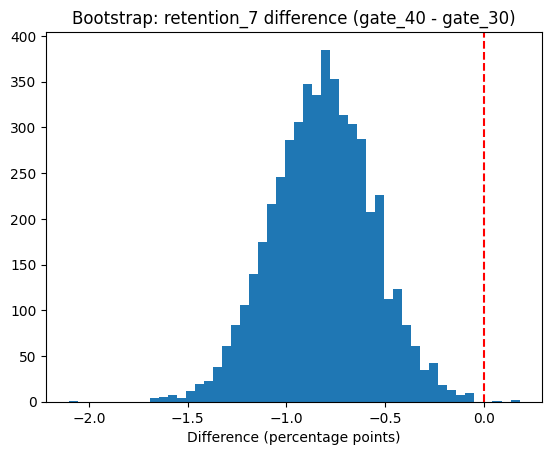

In [8]:
np.random.seed(42)

c7 = df_clean[df_clean["version"] == "gate_30"]["retention_7"].values
t7 = df_clean[df_clean["version"] == "gate_40"]["retention_7"].values

boot_diffs = []
for i in range(5000):
    bc = np.random.choice(c7, size=len(c7), replace=True).mean()
    bt = np.random.choice(t7, size=len(t7), replace=True).mean()
    boot_diffs.append(bt - bc)

boot_diffs = np.array(boot_diffs)

print("Average difference:", round(boot_diffs.mean()*100, 2), "points")
print("95% range:", np.round(np.percentile(boot_diffs, [2.5, 97.5])*100, 2))
print("Probability gate_30 is better:", round((boot_diffs < 0).mean()*100, 1), "%")

plt.hist(boot_diffs*100, bins=50)
plt.axvline(0, color="red", linestyle="--")
plt.title("Bootstrap: retention_7 difference (gate_40 - gate_30)")
plt.xlabel("Difference (percentage points)")
plt.show()

## 7. Rounds played: Mann-Whitney U test

Rounds are skewed, so a rank-based test is used instead of a t-test.

In [9]:
r_c = df_clean[df_clean["version"] == "gate_30"]["sum_gamerounds"]
r_t = df_clean[df_clean["version"] == "gate_40"]["sum_gamerounds"]

u_stat, p_mw = stats.mannwhitneyu(r_c, r_t, alternative="two-sided")

print("gate_30 median rounds:", r_c.median())
print("gate_40 median rounds:", r_t.median())
print("gate_30 mean rounds:", round(r_c.mean(), 2))
print("gate_40 mean rounds:", round(r_t.mean(), 2))
print("Mann-Whitney p-value:", round(p_mw, 4))

if p_mw < 0.05:
    print("Result: SIGNIFICANT")
else:
    print("Result: NOT significant")

gate_30 median rounds: 17.0
gate_40 median rounds: 16.0
gate_30 mean rounds: 51.34
gate_40 mean rounds: 51.3
Mann-Whitney p-value: 0.0509
Result: NOT significant


The result is borderline (p = 0.051). It shows no evidence of a difference in rounds played, which is not the same as proof that there is none.

## 8. Power analysis

What is the smallest difference this sample size can reliably detect (80% power)?

In [10]:
power = NormalIndPower()
base = 0.19            # approximate gate_30 retention_7
n_per_group = 44699    # size of the smaller group

# 1. Smallest detectable difference at 80% power
h = power.solve_power(nobs1=n_per_group, alpha=0.05, power=0.8, ratio=1.0)
phi = 2 * np.arcsin(np.sqrt(base))
detectable = np.sin((phi + h) / 2) ** 2
print("Smallest detectable difference in retention_7:",
      round((detectable - base) * 100, 2), "percentage points")

# 2. Sample size needed to detect a 1 point difference
effect = proportion_effectsize(base + 0.01, base)
needed = power.solve_power(effect_size=effect, alpha=0.05, power=0.8, ratio=1.0)
print("Users needed per group to detect 1 point difference:", round(needed))

Smallest detectable difference in retention_7: 0.74 percentage points
Users needed per group to detect 1 point difference: 24638


## 9. Player groups by rounds played (exploratory)

Where does the drop come from? Players are grouped by rounds played in the first 14 days.

**Caution:** rounds are measured *after* assignment, so the gate itself may have shaped them. Treat this as a pointer for follow-up tests, not proof of cause.

In [11]:
bins = [-1, 0, 5, 20, 100, df_clean["sum_gamerounds"].max()]
labels = ["0", "1-5", "6-20", "21-100", "100+"]
df_clean["bucket"] = pd.cut(df_clean["sum_gamerounds"], bins=bins, labels=labels)

seg = df_clean.groupby(["bucket", "version"], observed=True).agg(
    users=("userid", "count"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean"),
).round(4)
print(seg)

                users  retention_1  retention_7
bucket version                                 
0      gate_30   1937       0.0212       0.0083
       gate_40   2057       0.0224       0.0063
1-5    gate_30  10119       0.0731       0.0129
       gate_40  10604       0.0810       0.0144
6-20   gate_30  12428       0.3116       0.0503
       gate_40  12657       0.3064       0.0475
21-100 gate_30  14121       0.6998       0.2393
       gate_40  13881       0.6980       0.2184
100+   gate_30   6094       0.9022       0.7138
       gate_40   6290       0.8978       0.7124


## 10. Multiple-testing correction (Bonferroni)

Several tests were run on the same data, which raises the chance of a false positive. Bonferroni correction multiplies each p-value by the number of tests.

In [12]:
def ztest_p(data, metric):
    c = data[data["version"] == "gate_30"][metric]
    t = data[data["version"] == "gate_40"][metric]
    return proportions_ztest(np.array([c.sum(), t.sum()]),
                             np.array([len(c), len(t)]))[1]

# ---------- Part A: 3 main metrics ----------
p1 = ztest_p(df_clean, "retention_1")
p7 = ztest_p(df_clean, "retention_7")
p_rounds = stats.mannwhitneyu(r_c, r_t, alternative="two-sided")[1]

names = ["retention_1", "retention_7", "game rounds"]
raw_p = [p1, p7, p_rounds]
reject, adj_p, _, _ = multipletests(raw_p, alpha=0.05, method="bonferroni")

part_a = pd.DataFrame({"metric": names,
                       "raw_p": np.round(raw_p, 4),
                       "bonferroni_p": np.round(adj_p, 4),
                       "significant": reject})
print("PART A: main metrics")
print(part_a.to_string(index=False))

# ---------- Part B: 5 player groups (retention_7) ----------
seg_p = [ztest_p(df_clean[df_clean["bucket"] == b], "retention_7") for b in labels]
reject_s, adj_s, _, _ = multipletests(seg_p, alpha=0.05, method="bonferroni")

part_b = pd.DataFrame({"segment": labels,
                       "raw_p": np.round(seg_p, 4),
                       "bonferroni_p": np.round(adj_s, 4),
                       "significant": reject_s})
print()
print("PART B: player groups (retention_7)")
print(part_b.to_string(index=False))

PART A: main metrics
     metric  raw_p  bonferroni_p  significant
retention_1 0.0739        0.2218        False
retention_7 0.0016        0.0048         True
game rounds 0.0509        0.1527        False

PART B: player groups (retention_7)
segment  raw_p  bonferroni_p  significant
      0 0.4704        1.0000        False
    1-5 0.3588        1.0000        False
   6-20 0.3027        1.0000        False
 21-100 0.0000        0.0002         True
   100+ 0.8617        1.0000        False


The 7-day retention result survives the correction (adjusted p = 0.0048), and among player groups only the 21-100 rounds group shows a significant drop.

## 11. Bayesian A/B test

A Beta-Binomial model (uniform prior) gives the probability that each version is better, plus the *expected loss* of choosing each one.

--- retention_1 ---
Probability gate_30 is better: 96.29 %
Probability gate_40 is better: 3.71 %
Average difference: -0.59 points
95% credible interval: [-1.24  0.06]
Expected loss if we choose gate_40: 0.598 points
Expected loss if we choose gate_30: 0.005 points



--- retention_7 ---
Probability gate_30 is better: 99.92 %
Probability gate_40 is better: 0.08 %
Average difference: -0.82 points
95% credible interval: [-1.33 -0.3 ]
Expected loss if we choose gate_40: 0.816 points
Expected loss if we choose gate_30: 0.0 points



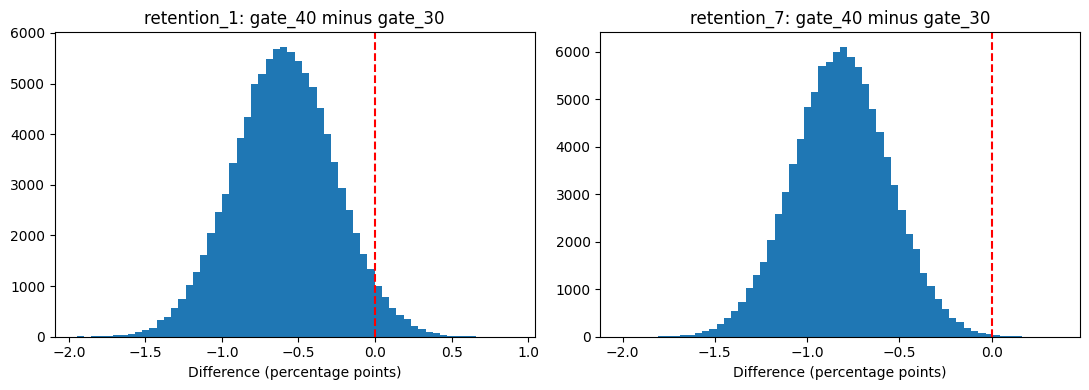

In [13]:
np.random.seed(42)
N = 100000

def bayes_ab(metric):
    c = df_clean[df_clean["version"] == "gate_30"][metric]
    t = df_clean[df_clean["version"] == "gate_40"][metric]

    # Beta distribution (uniform prior): successes + 1, failures + 1
    p_c = np.random.beta(1 + c.sum(), 1 + len(c) - c.sum(), N)
    p_t = np.random.beta(1 + t.sum(), 1 + len(t) - t.sum(), N)
    diff = (p_t - p_c) * 100

    print("---", metric, "---")
    print("Probability gate_30 is better:", round((p_c > p_t).mean() * 100, 2), "%")
    print("Probability gate_40 is better:", round((p_t > p_c).mean() * 100, 2), "%")
    print("Average difference:", round(diff.mean(), 2), "points")
    print("95% credible interval:", np.round(np.percentile(diff, [2.5, 97.5]), 2))
    print("Expected loss if we choose gate_40:", round(np.maximum(p_c - p_t, 0).mean() * 100, 3), "points")
    print("Expected loss if we choose gate_30:", round(np.maximum(p_t - p_c, 0).mean() * 100, 3), "points")
    print()
    return diff

diff1 = bayes_ab("retention_1")
diff7 = bayes_ab("retention_7")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, diff, title in zip(ax, [diff1, diff7], ["retention_1", "retention_7"]):
    a.hist(diff, bins=60)
    a.axvline(0, color="red", linestyle="--")
    a.set_title(title + ": gate_40 minus gate_30")
    a.set_xlabel("Difference (percentage points)")
plt.tight_layout()
plt.show()

## 12. Business impact (illustrative)

There is no revenue data, so the value per retained player is an **assumption** (Rs 50). Change `VALUE_PER_RETAINED` to the real figure when it is known. The number of players lost does not depend on this assumption.

In [14]:
# ===== ASSUMPTIONS (change these as needed) =====
INSTALLS = 100000        # new players (example)
VALUE_PER_RETAINED = 50  # value of one 7-day retained player in rupees (assumption)
# ================================================

c = df_clean[df_clean["version"] == "gate_30"]["retention_7"]
t = df_clean[df_clean["version"] == "gate_40"]["retention_7"]

p_c, p_t = c.mean(), t.mean()
diff = p_t - p_c
se = np.sqrt(p_c*(1-p_c)/len(c) + p_t*(1-p_t)/len(t))
low, high = diff - 1.96*se, diff + 1.96*se

print("Per", INSTALLS, "installs:")
print("Retained after 7 days with gate_30:", round(p_c * INSTALLS))
print("Retained after 7 days with gate_40:", round(p_t * INSTALLS))
print()

for label, x in [("Best estimate", diff),
                 ("Mildest case (95% CI)", high),
                 ("Worst case (95% CI)", low)]:
    lost_players = -x * INSTALLS
    lost_value = lost_players * VALUE_PER_RETAINED
    print(label)
    print("  Difference:", round(x*100, 2), "points")
    print("  Players lost:", round(lost_players))
    print("  Value lost: Rs", round(lost_value))

Per 100000 installs:
Retained after 7 days with gate_30: 19018
Retained after 7 days with gate_40: 18200

Best estimate
  Difference: -0.82 points
  Players lost: 818
  Value lost: Rs 40916
Mildest case (95% CI)
  Difference: -0.31 points
  Players lost: 310
  Value lost: Rs 15514
Worst case (95% CI)
  Difference: -1.33 points
  Players lost: 1326
  Value lost: Rs 66317


## 13. Final charts

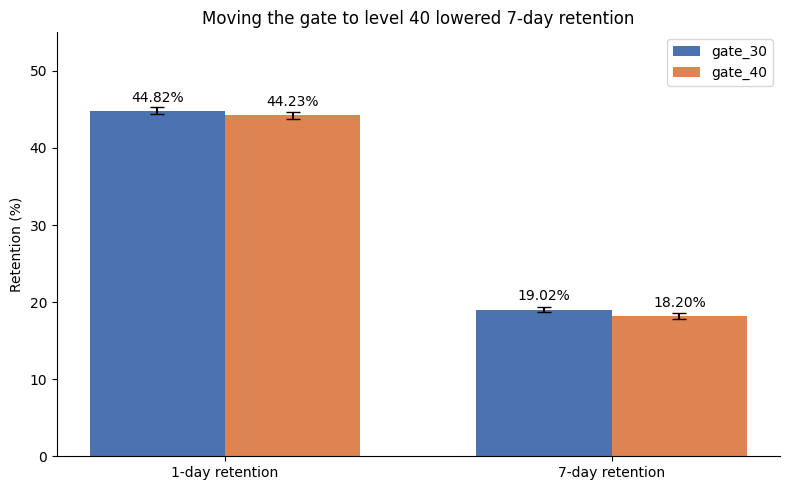

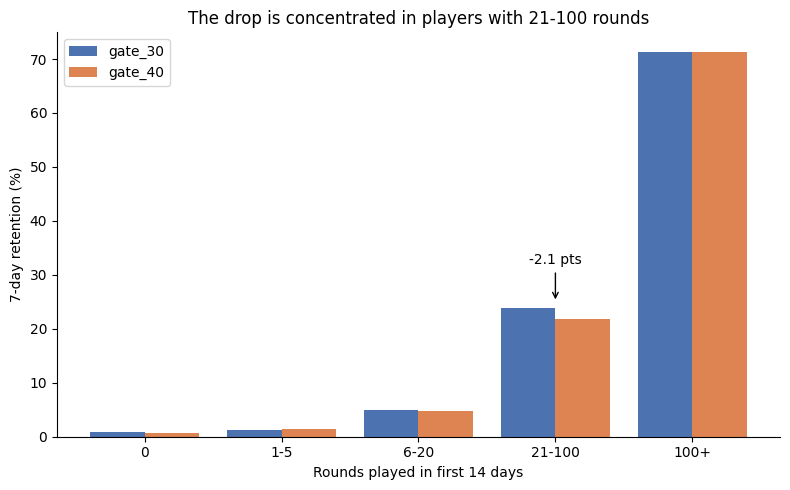

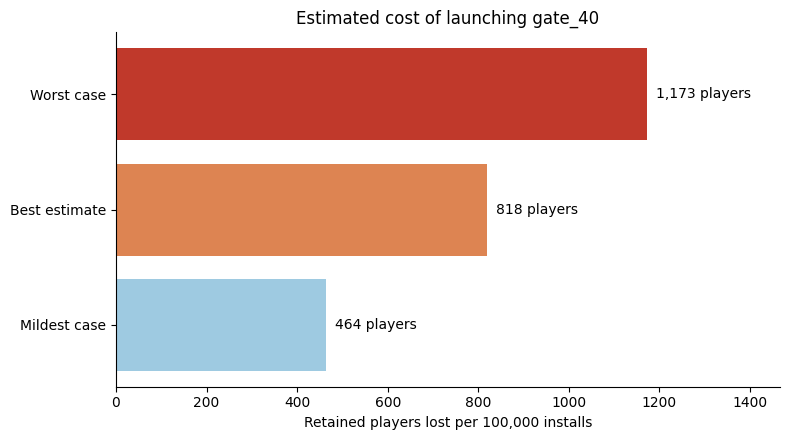

In [15]:
os.makedirs("charts", exist_ok=True)
C30, C40 = "#4C72B0", "#DD8452"

# ---------- Chart 1: Retention comparison with error bars ----------
fig, ax = plt.subplots(figsize=(8, 5))
metrics = ["retention_1", "retention_7"]
titles = ["1-day retention", "7-day retention"]
x = np.arange(len(metrics)); w = 0.35
for i, (ver, col) in enumerate([("gate_30", C30), ("gate_40", C40)]):
    vals, errs = [], []
    for m in metrics:
        s = df_clean[df_clean["version"] == ver][m]
        p = s.mean(); se = np.sqrt(p*(1-p)/len(s))
        vals.append(p*100); errs.append(1.96*se*100)
    bars = ax.bar(x + (i-0.5)*w, vals, w, yerr=errs, capsize=5, label=ver, color=col)
    for b, v in zip(bars, vals):
        ax.text(b.get_x()+b.get_width()/2, v+1.2, f"{v:.2f}%", ha="center", fontsize=10)
ax.set_xticks(x); ax.set_xticklabels(titles)
ax.set_ylabel("Retention (%)"); ax.set_ylim(0, 55)
ax.set_title("Moving the gate to level 40 lowered 7-day retention")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("charts/chart1_retention_comparison.png", dpi=200)
plt.show()

# ---------- Chart 2: Player groups ----------
pv = df_clean.pivot_table(index="bucket", columns="version", values="retention_7",
                          aggfunc="mean", observed=True) * 100

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(labels))
ax.bar(x-0.2, pv["gate_30"], 0.4, label="gate_30", color=C30)
ax.bar(x+0.2, pv["gate_40"], 0.4, label="gate_40", color=C40)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_xlabel("Rounds played in first 14 days")
ax.set_ylabel("7-day retention (%)")
ax.set_title("The drop is concentrated in players with 21-100 rounds")
i = labels.index("21-100")
ax.annotate("-2.1 pts", xy=(i, pv.loc["21-100", "gate_30"]+1),
            xytext=(i, pv.loc["21-100", "gate_30"]+8), ha="center",
            arrowprops=dict(arrowstyle="->"))
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("charts/chart2_segments.png", dpi=200)
plt.show()

# ---------- Chart 3: Business impact ----------
lost = [-(diff+1.96*se)*INSTALLS, -diff*INSTALLS, -(diff-1.96*se)*INSTALLS]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(["Mildest case", "Best estimate", "Worst case"], lost,
        color=["#9ecae1", "#DD8452", "#c0392b"])
for i, v in enumerate(lost):
    ax.text(v+20, i, f"{v:,.0f} players", va="center")
ax.set_xlim(0, max(lost)*1.25)
ax.set_xlabel("Retained players lost per 100,000 installs")
ax.set_title("Estimated cost of launching gate_40")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("charts/chart3_business_impact.png", dpi=200)
plt.show()

## 14. Conclusion

**Recommendation: keep the first gate at level 30.**

| Measure | gate_30 | gate_40 | Result |
| --- | --- | --- | --- |
| 7-day retention | 19.02% | 18.20% | Significant drop of 0.82 points (p = 0.0016, adjusted p = 0.0048) |
| 1-day retention | 44.82% | 44.23% | Not significant (p = 0.074) |
| Rounds played (median) | 17 | 16 | No evidence of a difference (p = 0.051) |

- Three methods agree on 7-day retention: Z-test, bootstrap and Bayesian analysis (99.9% probability that gate_30 is better).
- The drop is concentrated in players with 21 to 100 rounds (exploratory).
- Estimated impact: about 818 fewer retained players per 100,000 installs (range 310 to 1,326).

**Limitations:** only 7 days of retention, no revenue data (the Rs 50 value is an assumption), player-group results are exploratory, the group balance check was flagged (small gap), and the rounds result is borderline.

**Next steps:** run a follow-up test measuring 14 to 28 days of retention and revenue, and a targeted test for players with 21 to 100 rounds.